In [51]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler

In [52]:
def accuracy_naive(pred, test):
    N = len(test)
    errors = sum(abs(pred - test))
    return 1 - errors/N

In [53]:
def evaluate_probabilities(prob, true, model_name):
    """
    Evaluate probability predictions of a model_name with a number of different metrics
    """

    logloss = log_loss(y_true = true, y_proba = prob)
    roc_score  = roc_auc_score(y_true = true, y_score= prob)
    brier_score = brier_score_loss(y_true = true, y_proba = prob)

    print(f"Scores for the model: {model_name}: ")
    print(f"\nCross-entropy: {logloss}")
    print(f"\nAUC: {roc_score}")
    print(f"\nBrier Score: {brier_score}")

Fitting the models and naive accuracy test to see if they are working

In [54]:
df = pl.read_parquet("../data/processed_demos/economy_dataset.parquet")

In [55]:
df.head(10)

round_num,ct_equip_value,ct_buy_type,t_equip_value,t_buy_type,ct_win,equip_value_diff,equip_value_ratio,match_id
i32,i32,str,i32,str,i32,i32,f64,str
1,4800,"""pistol""",4200,"""pistol""",1,600,1.142823,"""aurora-vs-vitality-m1-anubis"""
2,22650,"""full""",14650,"""force""",1,8000,1.546038,"""aurora-vs-vitality-m1-anubis"""
3,28100,"""full""",2100,"""eco""",1,26000,13.375059,"""aurora-vs-vitality-m1-anubis"""
4,29500,"""full""",24050,"""full""",0,5450,1.226602,"""aurora-vs-vitality-m1-anubis"""
5,28100,"""full""",27650,"""full""",0,450,1.016274,"""aurora-vs-vitality-m1-anubis"""
6,6650,"""force""",27650,"""full""",1,-21000,0.240534,"""aurora-vs-vitality-m1-anubis"""
7,30300,"""full""",26950,"""full""",1,3350,1.1243,"""aurora-vs-vitality-m1-anubis"""
8,29950,"""full""",24550,"""full""",1,5400,1.21995,"""aurora-vs-vitality-m1-anubis"""
9,30150,"""full""",8950,"""force""",0,21200,3.36845,"""aurora-vs-vitality-m1-anubis"""


In [56]:
features = ["ct_equip_value", "t_equip_value", "equip_value_ratio"]

In [57]:
X = df[features].to_numpy()
Y = df["ct_win"].to_numpy()

In [58]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42, stratify=Y)
#scaler = StandardScaler()
#X_train = scaler.fit_transform(X_train)
#X_test = scaler.transform(X_test)

In [59]:
log_reg = LogisticRegression(random_state = 42)
log_reg = log_reg.fit(X_train, Y_train)

In [60]:
Y_pred_logreg = log_reg.predict(X_test)
accuracy_logreg = accuracy_naive(Y_pred_logreg, Y_test)
print(f"Accuracy for Logistical Regression: {accuracy_logreg}")

Accuracy for Logistical Regression: 0.6608187134502924


In [61]:
xgb = XGBClassifier(n_estimators=50, max_depth = 5, learning_rate = 0.1, objective="binary:logistic")
calibrated_xgb = CalibratedClassifierCV(xgb, method="isotonic", cv=5)
calibrated_xgb.fit(X_train, Y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","XGBClassifier...ree=None, ...)"
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...002952EB87540>, 

In [62]:
Y_pred_xgb = calibrated_xgb.predict(X_test)
accuracy_xgb= accuracy_naive(Y_pred_xgb, Y_test)
print(f"Accuracy for XGBoost: {accuracy_xgb}")

Accuracy for XGBoost: 0.6608187134502924


In [63]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam", random_state=42, learning_rate = "adaptive", max_iter=1000)
calibrated_mlp = CalibratedClassifierCV(mlp, method="isotonic", cv=5)
calibrated_mlp.fit(X_train, Y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",MLPClassifier...ndom_state=42)
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...002952EB879A0>, <s

In [64]:
Y_pred_mlp = calibrated_mlp.predict(X_test)
accuracy_mlp= accuracy_naive(Y_pred_mlp, Y_test)
print(f"Accuracy for Neural Network: {accuracy_mlp}")

Accuracy for Neural Network: 0.6842105263157895


Comparisons and tests for the models

In [65]:
Y_pred_logreg_prob = log_reg.predict_proba(X_test)[:, 1]
Y_pred_xgb_prob = calibrated_xgb.predict_proba(X_test)[:, 1]
Y_pred_mlp_prob = calibrated_mlp.predict_proba(X_test)[:, 1]

In [66]:
evaluate_probabilities(prob=Y_pred_logreg_prob, true=Y_test, model_name="Logistic Regression")

Scores for the model: Logistic Regression: 

Cross-entropy: 0.60630345951548

AUC: 0.7217045765963277

Brier Score: 0.2125686595157788


In [67]:
evaluate_probabilities(prob=Y_pred_xgb_prob, true=Y_test, model_name="XGBoost")

Scores for the model: XGBoost: 

Cross-entropy: 0.8503027456368761

AUC: 0.7079336804604001

Brier Score: 0.22761730063702892


In [68]:
evaluate_probabilities(prob=Y_pred_mlp_prob, true=Y_test, model_name="Multi-Layer Perceptron")

Scores for the model: Multi-Layer Perceptron: 

Cross-entropy: 0.6272523086402008

AUC: 0.7095094546451083

Brier Score: 0.21884555418621654


Conclusions:
Logistic Regression is more stable and more reliable.

Next step: Calibration Curve (Reliability Diagram):

Calculates the proportion of positive classes inside each bin on the probability predictions.


In [69]:
prob_true_lr, prob_pred_lr = calibration_curve(Y_test, Y_pred_logreg_prob, n_bins = 5, strategy="quantile")
prob_true_xgb, prob_pred_xgb = calibration_curve(Y_test, Y_pred_xgb_prob, n_bins = 5, strategy="quantile")
prob_true_mlp, prob_pred_mlp = calibration_curve(Y_test, Y_pred_mlp_prob, n_bins = 5, strategy="quantile")


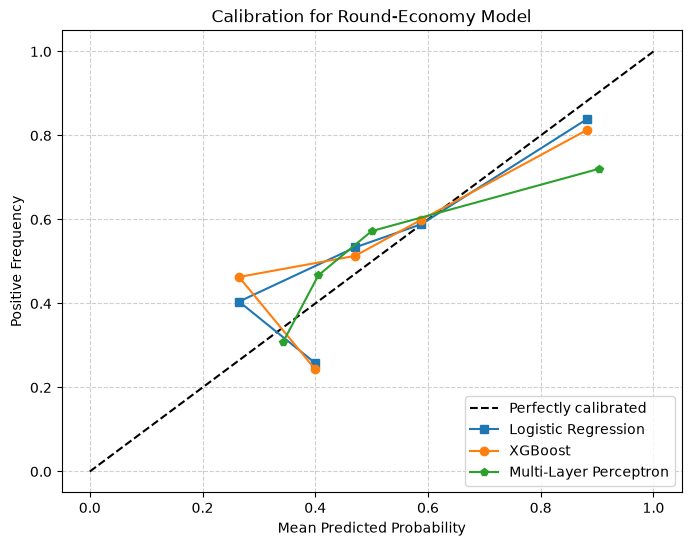

In [70]:
plt.figure(figsize=(8,6))

plt.plot([0,1], [0,1], "k--", label="Perfectly calibrated") # baseline line

plt.plot(prob_true_lr, prob_pred_lr, "s-", label = "Logistic Regression")
plt.plot(prob_true_xgb, prob_pred_xgb, "o-", label = "XGBoost")
plt.plot(prob_true_mlp, prob_pred_mlp, "p-", label = "Multi-Layer Perceptron")


plt.xlabel("Mean Predicted Probability")
plt.ylabel("Positive Frequency")
plt.title("Calibration for Round-Economy Model")
plt.legend(loc = "lower right")
plt.grid(True, linestyle="--", alpha = 0.6)
plt.show()